## Ejercicio 6

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [20]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [21]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [22]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

### Inciso a)

In [23]:
# Calculamos las mediciones ideales, sin ruido.
b7 = A7 @ x_fantoma

# Fijamos la semilla y generamos un vector normal de media 0 y desviación estándar 1.
rng = np.random.default_rng(67)
z = rng.standard_normal(b7.size)

# Calculamos el tamaño típico de las mediciones para ajustar la intensidad del ruido.
escala = np.sqrt(np.mean(b7**2))

In [24]:
# Probamos niveles de ruido del 0%, 1%, 3%, 6% y 10%.
sigmas = [0.0, 0.01, 0.03, 0.06, 0.10]
mediciones = {}
ruidos = {}

# Escalamos el mismo vector z y guardamos el ruido y las mediciones de cada caso.
for sigma in sigmas:
    eta_sigma = sigma * escala * z
    ruidos[sigma] = eta_sigma
    mediciones[sigma] = b7 + eta_sigma

# Mostramos la semilla, la escala utilizada y la cantidad de mediciones.
print("Semilla: 67")
print("Escala de las mediciones:", escala)
print("Cantidad de mediciones:", b7.size)

Semilla: 67
Escala de las mediciones: 1.0963269462661418
Cantidad de mediciones: 119


Usamos un único vector gaussiano `z` para todos los niveles así mantenemos la misma
realización del ruido y solamente modificamos su intensidad. La semilla permite repetir
exactamente el experimento en los ejercicios siguientes.

### Inciso b)

In [25]:
reconstrucciones = {}
resultados = []

for sigma in sigmas:
    # Reconstruimos la imagen a partir de las mediciones de cada nivel de ruido.
    b_sigma = mediciones[sigma]
    x_rec = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]
    reconstrucciones[sigma] = x_rec

    # Calculamos las normas del ruido y del residuo y el error respecto del fantoma.
    norma_ruido = np.linalg.norm(ruidos[sigma])
    norma_residuo = np.linalg.norm(b_sigma - A7 @ x_rec)
    error_relativo = np.linalg.norm(x_rec - x_fantoma) / np.linalg.norm(x_fantoma)
    minimo = x_rec.min()
    maximo = x_rec.max()

    # Guardamos y mostramos los resultados de este caso.
    resultados.append((sigma, norma_ruido, norma_residuo, error_relativo, minimo, maximo))
    print("Nivel de ruido:", sigma)
    print("Norma del ruido:", norma_ruido)
    print("Norma del residuo:", norma_residuo)
    print("Error relativo:", error_relativo)
    print("Valor mínimo:", minimo)
    print("Valor máximo:", maximo)
    print()

Nivel de ruido: 0.0
Norma del ruido: 0.0
Norma del residuo: 1.673576926985556e-14
Error relativo: 2.5738652865518797e-15
Valor mínimo: -1.3877787807814457e-15
Valor máximo: 0.8000000000000012

Nivel de ruido: 0.01
Norma del ruido: 0.11025791669633567
Norma del residuo: 0.0730573894882858
Error relativo: 0.02149415126427939
Valor mínimo: -0.018288177770511636
Valor máximo: 0.8078844804003749

Nivel de ruido: 0.03
Norma del ruido: 0.330773750089007
Norma del residuo: 0.219172168464857
Error relativo: 0.06448245379283753
Valor mínimo: -0.054864533311535735
Valor máximo: 0.8236534412011268

Nivel de ruido: 0.06
Norma del ruido: 0.661547500178014
Norma del residuo: 0.43834433692971386
Error relativo: 0.12896490758567475
Valor mínimo: -0.10972906662307236
Valor máximo: 0.8473068824022538

Nivel de ruido: 0.1
Norma del ruido: 1.102579166963357
Norma del residuo: 0.7305738948828566
Error relativo: 0.2149415126427902
Valor mínimo: -0.18288177770512076
Valor máximo: 0.8788448040037566



| σ | Norma del ruido | Norma del residuo | Error relativo | Mínimo | Máximo |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.0000e+00 | 1.3111e-14 | 0.000000 | -0.000000 | 0.800000 |
| 0.01 | 1.1026e-01 | 7.3057e-02 | 0.021494 | -0.018288 | 0.807884 |
| 0.03 | 3.3077e-01 | 2.1917e-01 | 0.064482 | -0.054865 | 0.823653 |
| 0.06 | 6.6155e-01 | 4.3834e-01 | 0.128965 | -0.109729 | 0.847307 |
| 0.1 | 1.1026e+00 | 7.3057e-01 | 0.214942 | -0.182882 | 0.878845 |

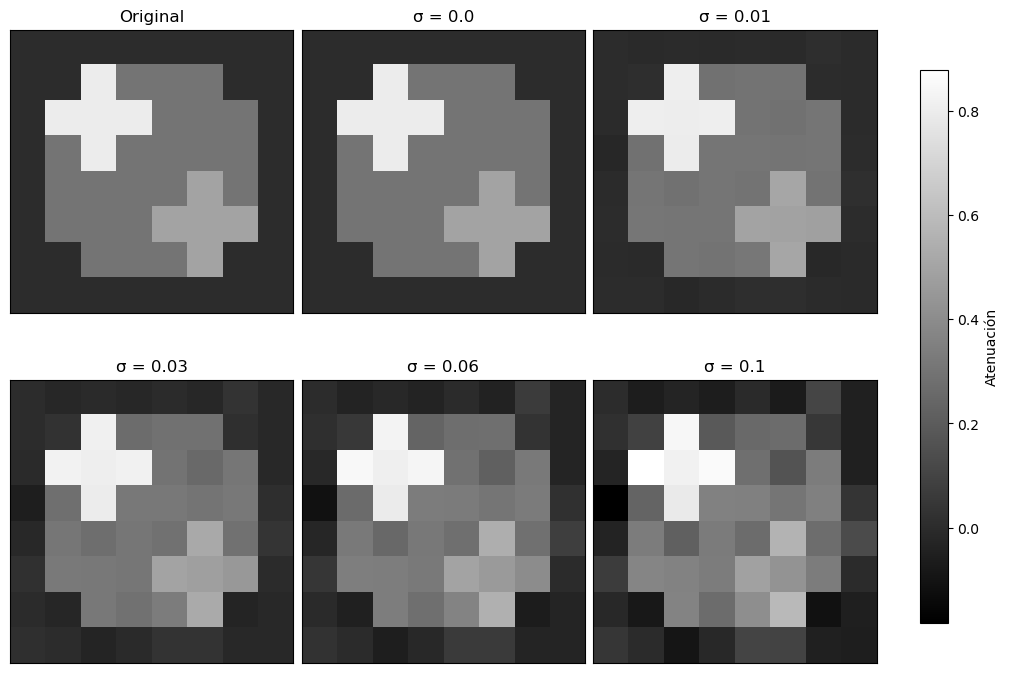

In [26]:
# Reunimos el fantoma original y las cinco reconstrucciones.
imagenes = [X_fantoma]
titulos = ["Original"]
for sigma in sigmas:
    imagenes.append(reconstrucciones[sigma].reshape(n, n))
    titulos.append("σ = " + str(sigma))

# Elegimos los mismos límites de color para todas las imágenes.
vmin = X_fantoma.min()
vmax = X_fantoma.max()
for imagen in imagenes:
    vmin = min(vmin, imagen.min())
    vmax = max(vmax, imagen.max())

# Mostramos las seis imágenes en dos filas de tres cuadros.
fig, axs = plt.subplots(2, 3, figsize=(10, 7), layout="constrained")
i = 0
for fila in range(2):
    for columna in range(3):
        axs[fila, columna].imshow(imagenes[i], cmap="gray", vmin=vmin, vmax=vmax)
        axs[fila, columna].set_title(titulos[i])
        axs[fila, columna].set_xticks([])
        axs[fila, columna].set_yticks([])
        i += 1

fig.colorbar(axs[0, 0].images[0], ax=axs, label="Atenuación", shrink=0.8)
plt.show()

### Inciso c)

Al aumentar $\sigma$ crecen el ruido y el error de reconstrucción. En esta realización,
el error relativo pasa de aproximadamente $0{,}0215$ para $\sigma=0{,}01$ a $0{,}2149$
para $\sigma=0{,}10$. Al usar el mismo vector de ruido y tener rango columna completo,
la perturbación de la solución depende linealmente de $\sigma$.

Sin ruido $b_7$ pertenece a $\operatorname{Col}(A_7)$. Al agregar ruido, en general
$b_\sigma$ queda fuera de ese subespacio y ninguna imagen reproduce todas sus componentes
exactamente. Mínimos cuadrados deja como residuo la parte que no puede explicar el modelo.

Pueden aparecer valores negativos porque `lstsq` minimiza el residuo sobre todos los vectores
de $\mathbb{R}^{64}$ y no impone atenuaciones no negativas. 